# Stress-Testing Experiments Evaluation

**Model :: CrossEfficientNet**

In this notebook we conduct targeted stress-testings experiments using the knowledge abstractions we create over augmented images. These stress-tests include:

- Over-all Performance
- Performance over Data Distributions (Native Benchmarks)
- Performance over Augmentation size
- Performance over Semantic Change (LANCE): cos-dist between caption embeddings
- Performance over entity groups (subject distributions)

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
import matplotlib.pyplot as plt
from tqdm import tqdm
import json
import ipdb

import warnings
warnings.filterwarnings('ignore')

### Data Paths & Data Loading

In [2]:
model = "UniversalFakeDetect"

# CSV files with model predictions:
INPAINT_EVAL = "UniversalFakeDetect/ufd_inpaint.csv"
LANCE_EVAL = "UniversalFakeDetect/ufd_lance.csv"

pred_files = [INPAINT_EVAL, LANCE_EVAL]

# extended metadata paths for all augmentations 
INPAINT_META = "inference_meta.csv"

#### Creating directory in which all computations will be saved

In [3]:
if not os.path.exists(model):
    os.mkdir(model)

### Data Loading (Predictions & Metadata)

In [4]:
def get_data_type(x):
    """
    Determines type from `model` column.
    """
    if x.model in ['RePaint', 'StableDiffusion']:
        return 'inpainting'
    elif x.model in ['lance']:
        return 'prompt-to-prompt'
    else:
        return 'real'


def load_model_predictions(pred_files, metadata=None):
    """
    Loads model predictions from a list of CSV files 
    and ensures all relevant metadata is present.
    
    Input:
        `pred_files` (list): list of CSV file paths with model predictions
        `metadata` (path): file path with image metadata. If not provided,
            the code assumes this information is already present in the
            prediction files.
    Output:
        `pred_df` (pd.DF): pandas DataFrame with model predictions and
            relevant metadata. 
    """
    
    pred_df = pd.concat([pd.read_csv(f) for f in pred_files])
    datasets = list(pred_df.dataset.unique())
    
    # standardizing dataset names if necessary:
    if 'ade20k' in datasets:
        pred_df['dataset'] = pred_df['dataset'].str.replace('ade20k', 'ADE20K')
        pred_df['dataset'] = pred_df['dataset'].str.replace('ade', 'ADE20K')
        pred_df['dataset'] = pred_df['dataset'].str.replace('helen', 'Helen')
        pred_df['dataset'] = pred_df['dataset'].str.replace('hpd', 'HumanParsing')
        pred_df['dataset'] = pred_df['dataset'].str.replace('celeba', 'CelebA-HQ')
        pred_df['dataset'] = pred_df['dataset'].str.replace('city', 'CityScapes')
        
    # checking for metadata information:
    if ('SA_change_category' not in pred_df.columns) \
    and ('semantic_change_category' not in pred_df.columns) \
    and metadata is not None:
        meta = pd.read_csv(metadata)['id', 'dataset', 'SA_change_category', 'semantic_change_category', 'pertrubation_type']
        pred_df = pred_df.merge(meta, how='left', on='id')
        
    elif ('SA_change_category' not in pred_df.columns) \
    and ('semantic_change_category' not in pred_df.columns):
        raise ValueError('Metadata information not detected in predictions file, but no metadata file provided. Please provide a path for `metadata`.')
        
    # adding `type` column, which is will be (inpainting, prompt-to-prompt, real)
    pred_df['type'] = pred_df.apply(get_data_type, axis=1)
        
    return pred_df



## Helper Functions

### Metric Computations

In [5]:
def compute_metrics(data_sample, model, group=None, fake_img_count=None, real_img_count=None):
    """
    This function will compute all relevant metrics for 
    a group of predictions. This includes the following:
    
        accuracy, precision, recall, f1, 
        precision-1, recall-1, f1-1,
        precision-0, recall-0, f1-0
        
    Metrics are returns in a pd.DataFrame.
    """
    
    if 'pred_binary' not in data_sample.columns:
        binary_preds = [1 if p >=0.5 else 0 for p in data_sample.pred]
        data_sample['pred_binary'] = binary_preds

    if 'label_binary' not in data_sample.columns:
        binary_labels = [1 if l == 'fake' else 0 for l in data_sample.label]
        data_sample['label_binary'] = binary_labels

    y_true = list(data_sample.label_binary)
    y_pred = list(data_sample.pred_binary)

    accuracy = accuracy_score(y_true, y_pred)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, beta=1.0, average='macro')
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, beta=1.0)

    metrics_df = pd.DataFrame()
    metrics_df['model'] = [model]
    if group:
        metrics_df['group'] = [group]
    if fake_img_count is not None:
        metrics_df['fake_imgs'] = [fake_img_count]
    if real_img_count is not None:
        metrics_df['real_imgs'] = [real_img_count]
    metrics_df['accuracy'] = [accuracy]
    metrics_df['precision'] = [precision_macro]
    metrics_df['recall'] = [recall_macro]
    metrics_df['f1'] = [f1_macro]
    metrics_df['precision_real'] = [precision[0]]
    metrics_df['precision_fake'] = [precision[1]]
    metrics_df['recall_real'] = [recall[0]]
    metrics_df['recall_fake'] = [recall[1]]
    metrics_df['f1_real'] = [f1[0]]
    metrics_df['f1_fake'] = [f1[1]]

    return metrics_df


def compute_fake_metrics(data_sample, model, group=None, fake_img_count=None):
    """
    This function will compute only positive class (fake) metrics for 
    a group of predictions. This includes the following:
    
        accuracy, precision-1, recall-1, f1-1,
        
    Metrics are returns in a pd.DataFrame.
    """
    
    if 'pred_binary' not in data_sample.columns:
        binary_preds = [1 if p >=0.5 else 0 for p in data_sample.pred]
        data_sample['pred_binary'] = binary_preds

    if 'label_binary' not in data_sample.columns:
        binary_labels = [1 if l == 'fake' else 0 for l in data_sample.label]
        data_sample['label_binary'] = binary_labels

    y_true = list(data_sample.label_binary)
    y_pred = list(data_sample.pred_binary)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, beta=1.0)

    metrics_df = pd.DataFrame()
    metrics_df['model'] = [model]
    if group:
        metrics_df['group'] = [group]
    if fake_img_count is not None:
        metrics_df['fake_imgs'] = [fake_img_count]
        
    # we do not show precision because it will always be 1:
    metrics_df['accuracy'] = [accuracy]
    metrics_df['recall_fake'] = [recall[1]]
    metrics_df['f1_fake'] = [f1[1]]

    return metrics_df


def save_metrics(metrics, root_dir, fname):
    """
    Saves metrics as a CSV file at the given
    root directory and the provided file name.
    """
    path = os.path.join(root_dir, fname)
    metrics.to_csv(path, index=False)
    print(f"Metrics saved at ::  {path}")



### Matplotlib Visualizations

In [6]:
def plot_all_metrics(metrics, group_names):
    """
    Plots all model performance metrics. This includes:
    Precision-1, Recall-1, Precision-0, Recall-0 
    
    """
    model = str(metrics.model.iloc[0])
    model_metrics = {}
    for i, grp in enumerate(group_names):
        mm = list(metrics.loc[metrics.group==grp][['precision_fake', 'recall_fake', 'precision_real', 'recall_real']].iloc[0])
        model_metrics[grp] = mm
    metric_names = ['Precision-1', 'Recall-1', 'Precision-0', 'Recall-0']
    
    index = range(len(metric_names))
    colors = plt.cm.Set2.colors
    plt.grid(True, linestyle='--', color='gray', linewidth=0.5)

    for i, grp in enumerate(model_metrics.keys()):
        bar_width = 0.8 / len(group_names)
        if i > 0:
            index = [j+bar_width for j in index]
        bars = plt.bar(index, model_metrics[grp], width=bar_width, label=grp, color=colors[i])
                
        # Add text labels on top of each bar
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2), ha='center', va='bottom')


    plt.xlabel('Metrics', fontweight="bold")
    plt.ylabel('Performance  (0 - 1)', fontweight="bold")
    plt.title(f'{model} Performance Comparison', fontweight="bold")
    
    tick_offset = -(bar_width/2)*(len(group_names)-1)
    plt.xticks([i + tick_offset for i in index], metric_names)  # Adjusting ticks position

    plt.legend()
    plt.tight_layout()  
    plt.show()
    
    
def plot_fake_metrics(metrics, group_names):
    """
    Plots fake-class specific metrics. This includes:
    Precision-1, Recall-1
    
    """
    model = str(metrics.model.iloc[0])
    model_metrics = {}
    for i, grp in enumerate(group_names):
        mm = list(metrics.loc[metrics.group==grp][['precision_fake', 'recall_fake']].iloc[0])
        model_metrics[grp] = mm
    metric_names = ['Precision-1', 'Recall-1']
    
    index = range(len(metric_names))
    colors = plt.cm.Set2.colors
    plt.grid(True, linestyle='--', color='gray', linewidth=0.5)

    for i, grp in enumerate(model_metrics.keys()):
        bar_width = 0.8 / len(group_names)
        if i > 0:
            index = [j+bar_width for j in index]
        bars = plt.bar(index, model_metrics[grp], width=bar_width, label=grp, color=colors[i])
        
        # Add text labels on top of each bar
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2), ha='center', va='bottom')

    plt.xlabel('Metrics', fontweight="bold")
    plt.ylabel('Performance  (0 - 1)', fontweight="bold")
    plt.title(f'{model} Performance Comparison', fontweight="bold")
    
    tick_offset = -(bar_width/2)*(len(group_names)-1)
    plt.xticks([i + tick_offset for i in index], metric_names)  # Adjusting ticks position

    plt.legend()
    plt.tight_layout()  
    plt.show()
    
    

### Seaborn Visualizations

In [7]:
import seaborn as sns
sns.set_theme(style="whitegrid")


def pivot_predictions(preds, fake_only=False):
    """
    Pivots the prediction DataFrame into a long format
    that will be easy to use with Seaborn plotting. 
    
    Currently only considers Precision & Recall metrics,
    will only retain metrics on the positive / "fake"
    class if `fake_only` == True.
    """
    preds = preds.rename(
        columns={'precision_real': 'Precision-0', 
                  'precision_fake': 'Precision-1',
                  'recall_real': 'Recall-0',
                  'recall_fake': 'Recall-1'
    })
    
    metrics = [m for m in preds.columns if 'Precision-' in m or 'Recall-' in m]
    if fake_only:
        metrics = [m for m in metrics if '1' in m]
        
    long_data = []
    for i, row in preds.iterrows():
        for m in metrics:
            d_ = {}
            d_['model'] = row.model
            d_['group'] = row.group
            d_['metric'] = m
            d_['value'] = row[m]
            long_data.append(d_)
          
    long_preds = pd.DataFrame(long_data)
    return long_preds


def plot_metrics_sns(preds, fake_only=False, title=None, save=True):
    """
    This function creates a seaborn bar plot demonstarting
    the performance metrics of a model on various "groups"
    of data.
    
    It will only visualize Precision & Recall metrics,
    will only retain metrics on the positive / "fake"
    class if `fake_only` == True.
    
    If `save` == True, the plots will save in a directory named
    after the model and named by the title of the plot.
    """
    long_preds = pivot_predictions(preds, fake_only=fake_only)
    model = preds.iloc[0].model
    sns.set_palette("Paired")

    g = sns.catplot(
        data=long_preds, kind="bar",
        x="metric", y="value", hue="group", alpha=.8, height=6
    )
    g.despine(left=True)
    g.legend.set_title("")
    
    for ax in g.axes.ravel():
        for c in ax.containers:
            ax.bar_label(c, fmt='%.2f')
            
    plt.xlabel("Metrics", fontsize=14, fontweight='bold');
    plt.ylabel("Performance Score (0 - 1)", fontsize=14, fontweight='bold');
    plt.tick_params(axis='both', which='major', labelsize=12)
    
    if title:
        plt.title(title, fontsize=16, fontweight='bold')
    else:
        plt.title(f"{model} Performance Metrics", fontsize=16, fontweight='bold')
        
    if save:
        fn = title.lower().replace("\n", " ").replace(" ", "_") + ".png"
        save_path = os.path.join(model, fn)
        plt.savefig(save_path, bbox_inches='tight')
        
    plt.show()



## General Performance

In [8]:
preds = load_model_predictions(pred_files, metadata=INPAINT_META)
preds.head()

,Unnamed: 0,dataset,image_path,id,name,pertrubation_type,change_value,model,SA_change_category,label,split,pred,type
0,2453,ADE20K,../data/ADE20K_People_256/images/ADE_train_000...,ADE_train_00020216,NaN,NaN,NaN,NaN,NaN,real,test,0.000764,real
1,2454,ADE20K,../data/ADE20K_People_256/images/ADE_train_000...,ADE_train_00002130,NaN,NaN,NaN,NaN,NaN,real,train,0.000044,real
2,2455,ADE20K,../data/ADE20K_People_256/images/ADE_frame_000...,ADE_frame_00000294,NaN,NaN,NaN,NaN,NaN,real,train,0.028391,real
3,2456,ADE20K,../data/ADE20K_People_256/images/ADE_train_000...,ADE_train_00019313,NaN,NaN,NaN,NaN,NaN,real,val,0.003019,real
4,2457,ADE20K,../data/ADE20K_People_256/images/ADE_train_000...,ADE_train_00024579,NaN,NaN,NaN,NaN,NaN,real,val,0.002981,real


### Inpainting

In [9]:
data_inpaint = preds.loc[(preds.type=='inpainting') | (preds.type=='real')]
metrics_df_inpaint = compute_metrics(data_inpaint, model, group='inpainting', fake_img_count=None, real_img_count=None)
metrics_df_inpaint

,model,group,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,inpainting,0.472822,0.639213,0.561391,0.431682,0.420955,0.857471,0.956338,0.166444,0.584589,0.278774


### Lance

In [10]:
data_lance = preds.loc[(preds.type=='prompt-to-prompt') | (preds.type=='real')]
metrics_df_lance = compute_metrics(data_lance, model, group='prompt-to-prompt')
metrics_df_lance

,model,group,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,prompt-to-prompt,0.790685,0.632494,0.548611,0.546993,0.813661,0.451327,0.956338,0.140884,0.879249,0.214737


### Visualization

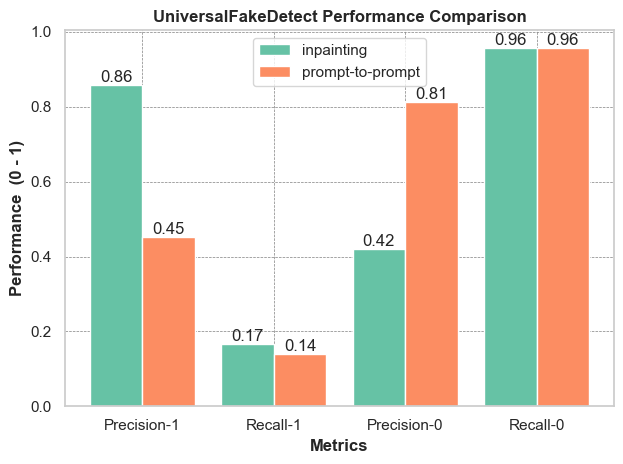

In [11]:
# combined metrics:
all_metrics_general = pd.concat([metrics_df_inpaint, metrics_df_lance])
plot_all_metrics(all_metrics_general, list(all_metrics_general.group))

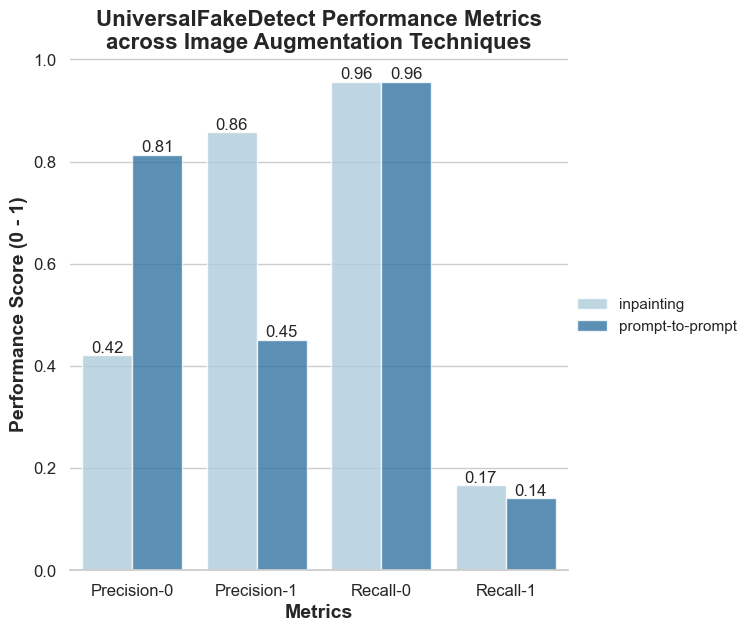

In [12]:
title = f"{model} Performance Metrics\nacross Image Augmentation Techniques"
plot_metrics_sns(all_metrics_general, fake_only=False, title=title)

## Performance across Benchmarks | Inpaint

In [13]:
groups = list(data_inpaint.dataset.unique())
groups

['ADE20K', 'CityScapes', 'CelebA-HQ', 'HumanParsing']

### Inpainting | ADE20K

In [14]:
inpaint_ade20k = data_inpaint.loc[data_inpaint.dataset==groups[0]]
fake_img_count = len(inpaint_ade20k.loc[inpaint_ade20k.label=='fake'])
real_img_count = len(inpaint_ade20k.loc[inpaint_ade20k.label=='real'])

metrics_df_ade20k = compute_metrics(inpaint_ade20k, model, group=groups[0], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_ade20k


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,ADE20K,655,358,0.385982,0.633318,0.522658,0.319326,0.364198,0.902439,0.988827,0.056489,0.532331,0.106322


### Inpainting | CityScapes

In [15]:
inpaint_cityscapes = data_inpaint.loc[data_inpaint.dataset==groups[1]]
fake_img_count = len(inpaint_cityscapes.loc[inpaint_cityscapes.label=='fake'])
real_img_count = len(inpaint_cityscapes.loc[inpaint_cityscapes.label=='real'])

metrics_df_cs = compute_metrics(inpaint_cityscapes, model, group=groups[1], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_cs

,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,CityScapes,287,338,0.5616,0.638915,0.524751,0.419775,0.553691,0.724138,0.976331,0.073171,0.706638,0.132911


### Inpainting | CelebA-HQ

In [16]:
inpaint_celeba = data_inpaint.loc[data_inpaint.dataset==groups[2]]
fake_img_count = len(inpaint_celeba.loc[inpaint_celeba.label=='fake'])
real_img_count = len(inpaint_celeba.loc[inpaint_celeba.label!='fake'])

metrics_df_celeba = compute_metrics(inpaint_celeba, model, group=groups[2], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_celeba


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,CelebA-HQ,612,374,0.420892,0.560263,0.521019,0.368098,0.39019,0.730337,0.935829,0.106209,0.550747,0.185449


### Inpainting | HumanParsing

In [17]:
inpaint_hp = data_inpaint.loc[data_inpaint.dataset==groups[3]]
fake_img_count = len(inpaint_hp.loc[inpaint_hp.label=='fake'])
real_img_count = len(inpaint_hp.loc[inpaint_hp.label!='fake'])

metrics_df_hp = compute_metrics(inpaint_hp, model, group=groups[3], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_hp


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,HumanParsing,687,350,0.55352,0.665776,0.644808,0.551235,0.425756,0.905797,0.925714,0.363901,0.583258,0.519211


### Visualization

In [18]:
all_metrics_inpaint = pd.concat([metrics_df_ade20k, metrics_df_cs, metrics_df_celeba, metrics_df_hp])
save_metrics(all_metrics_inpaint, model, "inpainting_dataset_metrics.csv")

all_metrics_inpaint


Metrics saved at ::  UniversalFakeDetect\inpainting_dataset_metrics.csv


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,ADE20K,655,358,0.385982,0.633318,0.522658,0.319326,0.364198,0.902439,0.988827,0.056489,0.532331,0.106322
0,UniversalFakeDetect,CityScapes,287,338,0.561600,0.638915,0.524751,0.419775,0.553691,0.724138,0.976331,0.073171,0.706638,0.132911
0,UniversalFakeDetect,CelebA-HQ,612,374,0.420892,0.560263,0.521019,0.368098,0.390190,0.730337,0.935829,0.106209,0.550747,0.185449
0,UniversalFakeDetect,HumanParsing,687,350,0.553520,0.665776,0.644808,0.551235,0.425756,0.905797,0.925714,0.363901,0.583258,0.519211


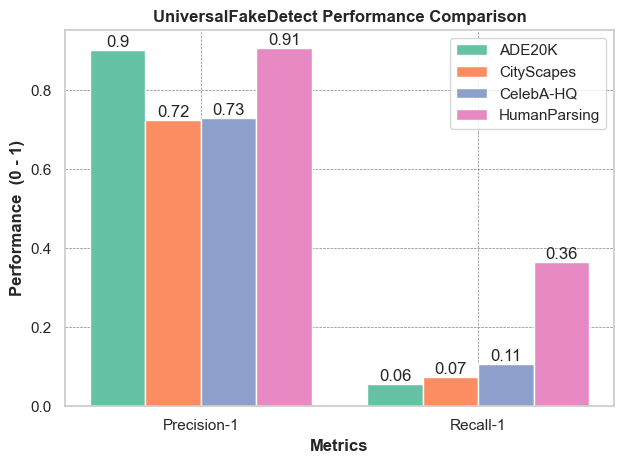

In [19]:
plot_fake_metrics(all_metrics_inpaint, list(all_metrics_inpaint.group))

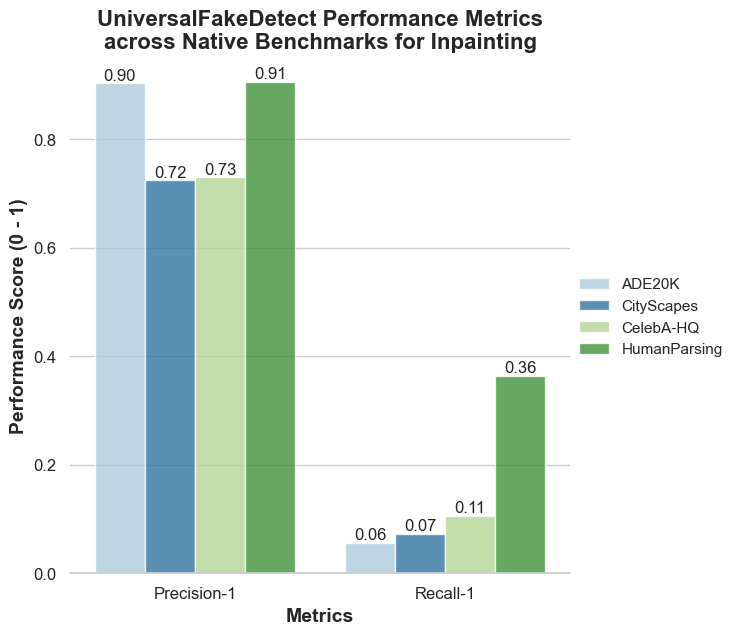

In [20]:
title = f"{model} Performance Metrics\nacross Native Benchmarks for Inpainting"
plot_metrics_sns(all_metrics_inpaint, fake_only=True, title=title)

## Performance across Benchmarks | LANCE

In [21]:
groups = list(data_lance.dataset.unique())
groups

['ADE20K', 'CityScapes', 'CelebA-HQ', 'HumanParsing']

### Lance | ADE20K

In [22]:
lance_ade20k = data_lance.loc[data_lance.dataset==groups[0]]
fake_img_count = len(lance_ade20k.loc[lance_ade20k.label=='fake'])
real_img_count = len(lance_ade20k.loc[lance_ade20k.label=='real'])

metrics_df_ade20k = compute_metrics(lance_ade20k, model, group=groups[0], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_ade20k


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,ADE20K,117,358,0.781053,0.79463,0.567063,0.559149,0.779736,0.809524,0.988827,0.145299,0.871921,0.246377


### Lance | CityScapes

In [23]:
lance_cityscapes = data_lance.loc[data_lance.dataset==groups[1]]
fake_img_count = len(lance_cityscapes.loc[lance_cityscapes.label=='fake'])
real_img_count = len(lance_cityscapes.loc[lance_cityscapes.label=='real'])

metrics_df_cs = compute_metrics(lance_cityscapes, model, group=groups[1], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_cs


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,CityScapes,120,338,0.751092,0.696622,0.546499,0.524948,0.756881,0.636364,0.976331,0.116667,0.852713,0.197183


### Lance | CelebA-HQ

In [24]:
lance_celeba = data_lance.loc[data_lance.dataset==groups[2]]
fake_img_count = len(lance_celeba.loc[lance_celeba.label=='fake'])
real_img_count = len(lance_celeba.loc[lance_celeba.label=='real'])

metrics_df_celeba = compute_metrics(lance_celeba, model, group=groups[2], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_celeba


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,CelebA-HQ,60,374,0.824885,0.560323,0.534581,0.537987,0.870647,0.25,0.935829,0.133333,0.902062,0.173913


### Lance | HumanParsing

In [25]:
lance_hp = data_lance.loc[data_lance.dataset==groups[3]]
fake_img_count = len(lance_hp.loc[lance_hp.label=='fake'])
real_img_count = len(lance_hp.loc[lance_hp.label=='real'])

metrics_df_hp = compute_metrics(lance_hp, model, group=groups[3], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_hp


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,UniversalFakeDetect,HumanParsing,65,350,0.809639,0.587603,0.555165,0.562172,0.859416,0.315789,0.925714,0.184615,0.891334,0.23301


### Lance | Helen

In [26]:
lance_hp = data_lance.loc[data_lance.dataset==groups[4]]
fake_img_count = len(lance_hp.loc[lance_hp.label=='fake'])
real_img_count = len(lance_hp.loc[lance_hp.label=='real'])

metrics_df_helen = compute_metrics(lance_hp, model, group=groups[4], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_helen


IndexError: list index out of range

### Visualization

In [27]:
all_metrics_lance = pd.concat([metrics_df_ade20k, metrics_df_cs, metrics_df_celeba, metrics_df_hp])
save_metrics(all_metrics_lance, model, "p2p_dataset_metrics.csv")

all_metrics_lance


NameError: name 'metrics_df_helen' is not defined

In [28]:
title = f"{model} Performance Metrics\nacross Native Benchmarks for Prompt-to-Prompt"
plot_metrics_sns(all_metrics_lance, fake_only=True, title=title)


NameError: name 'all_metrics_lance' is not defined

## Performance across SA bins | Inpaint

This surveys the fluctuation in model performance across area of augmentation

### Small | Bin = 1

In [32]:
inpaint_1 = preds.loc[preds.SA_change_category==1.0]
fake_img_count = len(inpaint_1.loc[inpaint_1.label=='fake'])
real_img_count = len(inpaint_1.loc[inpaint_1.label=='real'])

metrics_df_1 = compute_fake_metrics(inpaint_1, model, group='bin: 1', fake_img_count=fake_img_count)
metrics_df_1

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 1,518,0.830116,0.830116,0.907173


### Small_Medium | Bin = 2

In [33]:
inpaint_2 = preds.loc[preds.SA_change_category==2.0]
fake_img_count = len(inpaint_2.loc[inpaint_2.label=='fake'])
real_img_count = len(inpaint_2.loc[inpaint_2.label=='real'])

metrics_df_2 = compute_fake_metrics(inpaint_2, model, group='bin: 2', fake_img_count=fake_img_count)
metrics_df_2

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 2,924,0.838745,0.838745,0.912301


### Medium | Bin = 3

In [34]:
inpaint_3 = preds.loc[preds.SA_change_category==3.0]
fake_img_count = len(inpaint_3.loc[inpaint_3.label=='fake'])
real_img_count = len(inpaint_3.loc[inpaint_3.label=='real'])

metrics_df_3 = compute_fake_metrics(inpaint_3, model, group='bin: 3', fake_img_count=fake_img_count)
metrics_df_3

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 3,527,0.802657,0.802657,0.890526


### Medium-Large | Bin = 4

In [35]:
inpaint_4 = preds.loc[preds.SA_change_category==4.0]
fake_img_count = len(inpaint_4.loc[inpaint_4.label=='fake'])
real_img_count = len(inpaint_4.loc[inpaint_4.label=='real'])

metrics_df_4 = compute_fake_metrics(inpaint_4, model, group='bin: 4', fake_img_count=fake_img_count)
metrics_df_4

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 4,366,0.745902,0.745902,0.85446


### Large | Bin = 5

In [36]:
inpaint_5 = preds.loc[preds.SA_change_category==5.0]
fake_img_count = len(inpaint_5.loc[inpaint_5.label=='fake'])
real_img_count = len(inpaint_5.loc[inpaint_5.label=='real'])

metrics_df_5 = compute_fake_metrics(inpaint_5, model, group='bin: 5', fake_img_count=fake_img_count)
metrics_df_5

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 5,268,0.783582,0.783582,0.878661


### Visualization

#### Bar

In [37]:
sa_bin_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
save_metrics(sa_bin_metrics, model, "inpainting_surface_area_metrics.csv")

sa_bin_metrics


Metrics saved at ::  DinoV2\inpainting_surface_area_metrics.csv


,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 1,518,0.830116,0.830116,0.907173
0,DinoV2,bin: 2,924,0.838745,0.838745,0.912301
0,DinoV2,bin: 3,527,0.802657,0.802657,0.890526
0,DinoV2,bin: 4,366,0.745902,0.745902,0.854460
0,DinoV2,bin: 5,268,0.783582,0.783582,0.878661


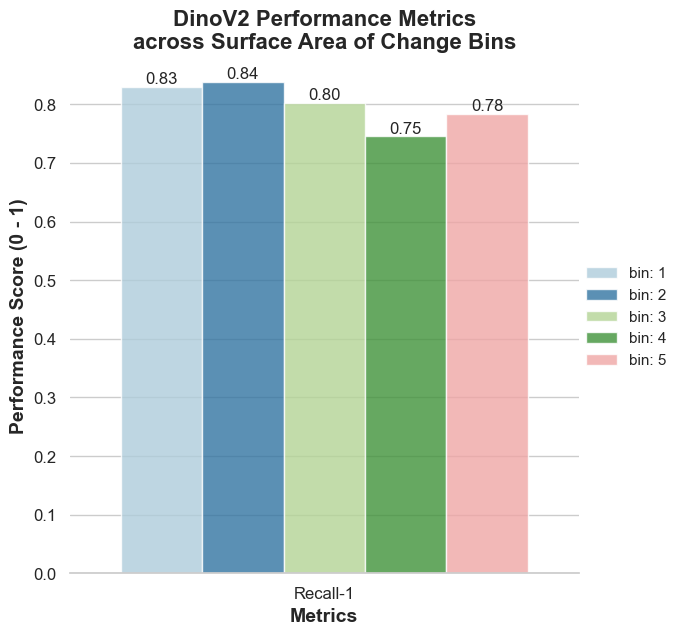

In [38]:
title = f"{model} Performance Metrics\nacross Surface Area of Change Bins"
plot_metrics_sns(sa_bin_metrics, fake_only=True, title=title)

#### Heatmaps

In [39]:
## OLD CODE - DONT USE

import matplotlib.pyplot as plt
import numpy as np


# join all performance metrics:
all_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
all_metrics = all_metrics.sort_values(by=['group'])
all_metrics['precision_fake'] = all_metrics.precision_fake.apply(lambda x: round(x, 2))
all_metrics['recall_fake'] = all_metrics.recall_fake.apply(lambda x: round(x, 2))


# Sample precision and recall scores for four different models
models = list(all_metrics.group)
precision = list(all_metrics.precision_fake)
recall = list(all_metrics.recall_fake)

# Create a 2D array for precision and recall scores
scores = np.array([precision, recall])

# Create the heatmap
plt.figure(figsize=(8, 6))
plt.imshow(scores, cmap='viridis', interpolation='nearest', vmin=0.0, vmax=1.0)

# Add color bar
plt.colorbar(label='Score')

# Set the tick labels
plt.xticks(np.arange(len(models)), models)
plt.yticks(np.arange(2), ['Precision-Fake', 'Recall-Fake'])

# Add text annotations
for i in range(len(models)):
    for j in range(2):
        plt.text(i, j, str(scores[j, i]), ha='center', va='center', color='white')

# Set axis labels and title
plt.xlabel('Surface Area Change Categories (Small --> Large)')
plt.ylabel('Metrics')
plt.title('Precision-1 and Recall-1 Scores for CrossEfficientNet')

# Show plot
plt.tight_layout()
plt.show()

AttributeError: 'DataFrame' object has no attribute 'precision_fake'

## Performance across Semantic Change bins | Lance

This surveys the fluctuation in model performance across area of augmentation

### Small | Bin = 1

In [40]:
lance_1 = preds.loc[preds.semantic_change_category==1.0]
fake_img_count = len(lance_1.loc[lance_1.label=='fake'])
real_img_count = len(lance_1.loc[lance_1.label=='real'])

metrics_df_1 = compute_fake_metrics(lance_1, model, group='bin: 1', fake_img_count=fake_img_count)
metrics_df_1

AttributeError: 'DataFrame' object has no attribute 'semantic_change_category'

### Small_Medium | Bin = 2

In [41]:
lance_2 = preds.loc[preds.semantic_change_category==2.0]
fake_img_count = len(lance_2.loc[lance_2.label=='fake'])
real_img_count = len(lance_2.loc[lance_2.label=='real'])

metrics_df_2 = compute_fake_metrics(lance_2, model, group='bin: 2', fake_img_count=fake_img_count)
metrics_df_2

AttributeError: 'DataFrame' object has no attribute 'semantic_change_category'

### Medium | Bin = 3

In [42]:
lance_3 = preds.loc[preds.semantic_change_category==3.0]
fake_img_count = len(lance_3.loc[lance_3.label=='fake'])
real_img_count = len(lance_3.loc[lance_3.label=='real'])

metrics_df_3 = compute_fake_metrics(lance_3, model, group='bin: 3', fake_img_count=fake_img_count)
metrics_df_3

AttributeError: 'DataFrame' object has no attribute 'semantic_change_category'

### Medium-Large | Bin = 4

In [43]:
lance_4 = preds.loc[preds.semantic_change_category==4.0]
fake_img_count = len(lance_4.loc[lance_4.label=='fake'])
real_img_count = len(lance_4.loc[lance_4.label=='real'])

metrics_df_4 = compute_fake_metrics(lance_4, model, group='bin: 4', fake_img_count=fake_img_count)
metrics_df_4

AttributeError: 'DataFrame' object has no attribute 'semantic_change_category'

### Large | Bin = 5

In [44]:
lance_5 = preds.loc[preds.semantic_change_category==5.0]
fake_img_count = len(lance_5.loc[lance_5.label=='fake'])
real_img_count = len(lance_5.loc[lance_5.label=='real'])

metrics_df_5 = compute_fake_metrics(lance_5, model, group='bin: 5', fake_img_count=fake_img_count)
metrics_df_5

AttributeError: 'DataFrame' object has no attribute 'semantic_change_category'

### Visualization

In [45]:
semantic_bin_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
save_metrics(semantic_bin_metrics, model, "p2p_semantic_change_metrics.csv")

semantic_bin_metrics

Metrics saved at ::  DinoV2\p2p_semantic_change_metrics.csv


,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,bin: 1,518,0.830116,0.830116,0.907173
0,DinoV2,bin: 2,924,0.838745,0.838745,0.912301
0,DinoV2,bin: 3,527,0.802657,0.802657,0.890526
0,DinoV2,bin: 4,366,0.745902,0.745902,0.854460
0,DinoV2,bin: 5,268,0.783582,0.783582,0.878661


#### Bar

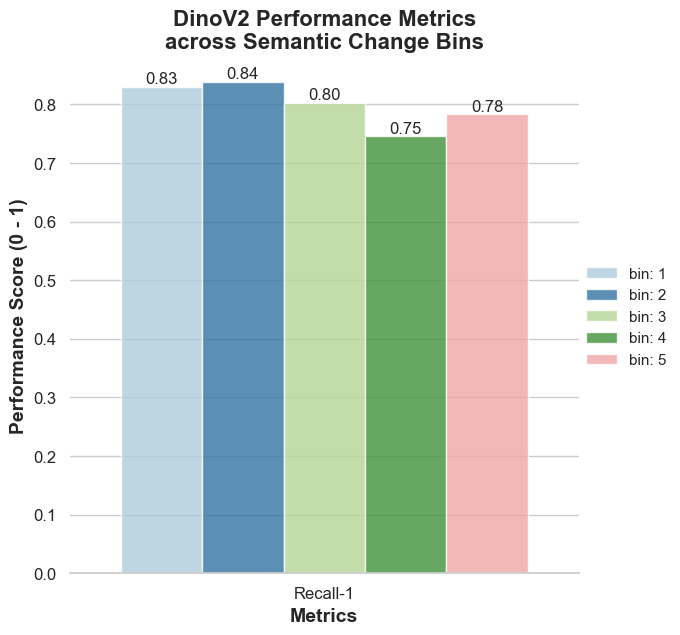

In [46]:
title = f"{model} Performance Metrics\nacross Semantic Change Bins"
plot_metrics_sns(semantic_bin_metrics, fake_only=True, title=title)

#### Heatmaps

In [47]:
## OLD CODE - DONT USE

import matplotlib.pyplot as plt
import numpy as np


# join all performance metrics:
all_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
all_metrics = all_metrics.sort_values(by=['group'])
all_metrics['precision_fake'] = all_metrics.precision_fake.apply(lambda x: round(x, 2))
all_metrics['recall_fake'] = all_metrics.recall_fake.apply(lambda x: round(x, 2))


# Sample precision and recall scores for four different models
models = list(all_metrics.group)
precision = list(all_metrics.precision_fake)
recall = list(all_metrics.recall_fake)

# Create a 2D array for precision and recall scores
scores = np.array([precision, recall])

# Create the heatmap
plt.figure(figsize=(8, 6))
plt.imshow(scores, cmap='viridis', interpolation='nearest', vmin=0.0, vmax=1.0)

# Add color bar
plt.colorbar(label='Score')

# Set the tick labels
plt.xticks(np.arange(len(models)), models)
plt.yticks(np.arange(2), ['Precision-Fake', 'Recall-Fake'])

# Add text annotations
for i in range(len(models)):
    for j in range(2):
        plt.text(i, j, str(scores[j, i]), ha='center', va='center', color='white')

# Set axis labels and title
plt.xlabel('Semantic Change Categories (Small --> Large)')
plt.ylabel('Metrics')
plt.title('Precision-1 and Recall-1 Scores for CrossEfficientNet')

# Show plot
plt.tight_layout()
plt.show()

AttributeError: 'DataFrame' object has no attribute 'precision_fake'

## Performance across Augmentation Type | Lance

This surveys the fluctuation in model performance across types of augmentations conducted with prompt-to-prompt techniques:

In [48]:
preds.pertrubation_type.unique()

array([nan, 'adjective', 'background', 'object', 'subject', 'weather'],
      dtype=object)

### Adjective

In [49]:
group = 'adjective'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_adj = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_adj

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,adjective,74,0.810811,0.810811,0.895522


### Object

In [50]:
group = 'object'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_obj = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_obj

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,object,94,0.744681,0.744681,0.853659


### Subject

In [51]:
group = 'subject'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_sub = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_sub

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,subject,145,0.827586,0.827586,0.90566


### Weather

In [52]:
group = 'weather'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_w = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_w

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,weather,14,0.571429,0.571429,0.727273


### Background

In [53]:
group = 'background'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_back = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_back

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,background,35,0.6,0.6,0.75


### Visualization

In [54]:
pert_type_metrics = pd.concat([metrics_df_adj, metrics_df_obj, metrics_df_sub, metrics_df_w, metrics_df_back])
save_metrics(pert_type_metrics, model, "p2p_perturb_type_metrics.csv")

pert_type_metrics


Metrics saved at ::  DinoV2\p2p_perturb_type_metrics.csv


,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,DinoV2,adjective,74,0.810811,0.810811,0.895522
0,DinoV2,object,94,0.744681,0.744681,0.853659
0,DinoV2,subject,145,0.827586,0.827586,0.905660
0,DinoV2,weather,14,0.571429,0.571429,0.727273
0,DinoV2,background,35,0.600000,0.600000,0.750000


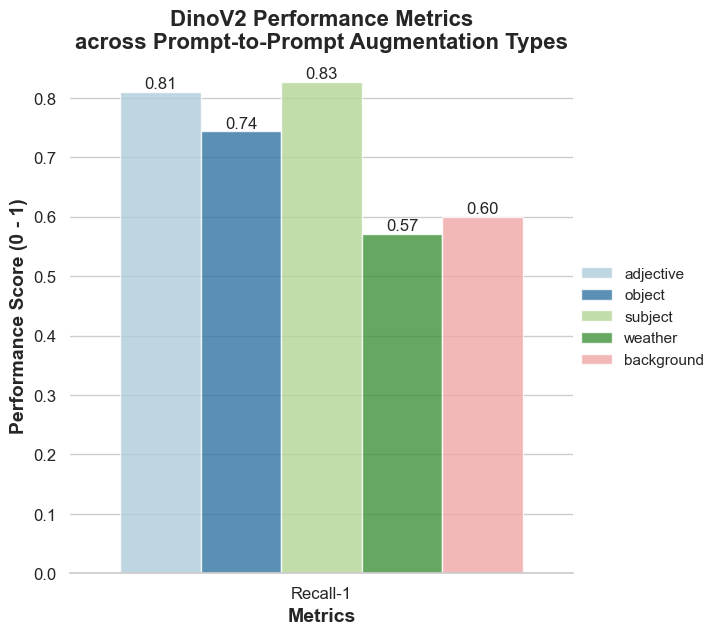

In [55]:
title = f"{model} Performance Metrics\nacross Prompt-to-Prompt Augmentation Types"
plot_metrics_sns(pert_type_metrics, fake_only=True, title=title)